# Graphs and reinforcement learning

In [139]:
import pandas as pd
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

FS = 15

In [2]:
%matplotlib inline

# Make a simple graph

In [445]:
def draw_graph(start=None, goal=None, route=None):
    nx.draw_networkx_nodes(G, pos)
    nx.draw_networkx_edges(G, pos)
    nx.draw_networkx_labels(G, pos, font_color='w')
    if start:
        nx.draw_networkx_nodes(G, pos, nodelist=[start], node_color='g')
    if goal:
        nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_color='r')
    if route:
        kwargs = dict(edge_color='r', width=3, style='solid')
        nx.draw_networkx_edges(G, pos, edgelist=route, **kwargs)
    plt.show()

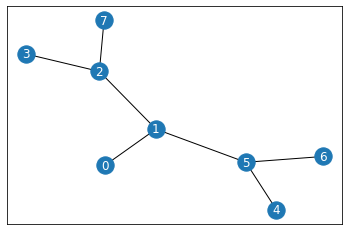

In [419]:
# Make the graph
points_list = [(0, 1), (1, 5), (5, 6), (5, 4), (1, 2), (2, 3), (2, 7)]
G = nx.Graph()
G.add_edges_from(points_list)
pos = nx.spring_layout(G)
draw_graph()

### Create the reward graph

In [165]:
MATRIX_SIZE = len(G.nodes)
R = -1 * np.matrix(np.ones(shape=(MATRIX_SIZE, MATRIX_SIZE)))

# assign zeros to paths and 100 to goal-reaching point
goal = 7
for point in points_list:
    print(point)
    R[point] = 100 if point[1] == goal else 0    
    R[point[::-1]] = 100 if point[0] == goal else 0

# add goal point round trip
R[goal, goal]= 100

(0, 1)
(1, 5)
(5, 6)
(5, 4)
(1, 2)
(2, 3)
(2, 7)


# Set up the Q-learning

In [278]:
def get_available_actions(state):
    current_state_row = R[state, ]
    return np.where(current_state_row >= 0)[1]

def sample_next_action(available_actions_range):
    next_action = int(np.random.choice(available_actions, 1))
    return next_action

def update(current_state, action, gamma):
    max_idx = np.where(Q[action, ] == np.max(Q[action, ]))[1]
    
    if max_idx.shape[0] > 1:
        max_idx = int(np.random.choice(max_idx, size=1))
    else:
        max_idx = int(max_idx)
    max_value = Q[action, max_idx]
    
    Q[current_state, action] = R[current_state, action] + gamma * max_value
    return (np.sum(Q / np.max(Q) * 100)) if (np.max(Q) > 0) else (0)

## Train the model

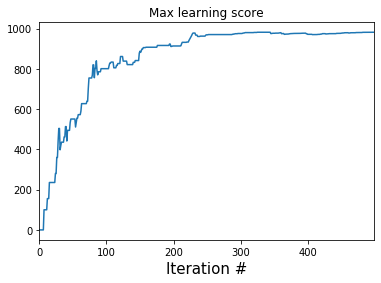

Trained Q matrix:


matrix([[  0.        ,  63.90499184,   0.        ,   0.        ,
           0.        ,   0.        ,   0.        ,   0.        ],
        [ 51.12399347,   0.        ,  79.8812398 ,   0.        ,
           0.        ,  51.12399347,   0.        ,   0.        ],
        [  0.        ,  63.90499184,   0.        ,  64.        ,
           0.        ,   0.        ,   0.        , 100.        ],
        [  0.        ,   0.        ,  80.        ,   0.        ,
           0.        ,   0.        ,   0.        ,   0.        ],
        [  0.        ,   0.        ,   0.        ,   0.        ,
           0.        ,  51.12399347,   0.        ,   0.        ],
        [  0.        ,  63.90499184,   0.        ,   0.        ,
          40.89919478,   0.        ,  40.89919478,   0.        ],
        [  0.        ,   0.        ,   0.        ,   0.        ,
           0.        ,  51.12399347,   0.        ,   0.        ],
        [  0.        ,   0.        ,  80.        ,   0.        ,
           0.     

In [307]:
# Initialize the "brain" matrix
Q = np.matrix(np.zeros([MATRIX_SIZE, MATRIX_SIZE]))

# Set the learning parameter
gamma = 0.8

# Training
scores = []
for i in range(500):
    current_state = np.random.randint(0, MATRIX_SIZE)
    available_actions = get_available_actions(current_state)
    action = sample_next_action(available_actions)
    score = update(current_state, action, gamma)
    scores.append(score)
ax = pd.Series(scores).plot(title='Max learning score')
ax.set_xlabel('Iteration #', fontsize=FS)
plt.show()
    
print("Trained Q matrix:")
Q = Q / np.max(Q) * 100
Q

### Test the model

In [451]:
def find_next_step(current_state):
    return np.where(Q[current_state, ] == np.max(Q[current_state, ]))[1]

def get_edges_from_nodes(nodes):
    edges = []
    for i in range(len(steps) - 1):
        edges.append(tuple(steps[i:i + 2]))
    return edges

Most efficient path: [6, 5, 1, 2, 7]


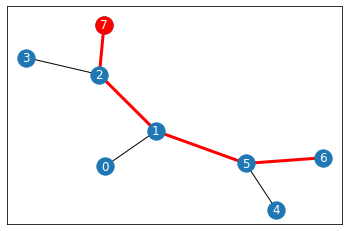

In [461]:
initial_state = 6
current_state = initial_state
steps = [current_state]
while current_state != goal:
    next_step_index = find_next_step(current_state)
    
    if next_step_index.shape[0] > 1:
        next_step_index = np.random.choice(next_step_index, size=1)
    next_step_index = int(next_step_index)
    
    steps.append(next_step_index)
    current_state = next_step_index

print(f"Most efficient path: {steps}")
route = get_edges_from_nodes(steps)
draw_graph(goal=goal, route=route)